# TP 3 — Réseau informé par la physique (PINN)
**Chapitre 1 · Fondements de l'IA générative** — durée indicative : 1 h

Idée : au lieu d'apprendre seulement à partir de données, on pénalise la violation d'une **équation différentielle** connue. La dérivée de la sortie du réseau par rapport à son entrée est obtenue par `autograd`.

Problème : décroissance exponentielle
$$\frac{du}{dt} = -k\,u, \qquad u(0)=1, \qquad t\in[0, 2],\; k=2.$$
Solution exacte : $u(t) = e^{-kt}$.

In [1]:
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
torch.manual_seed(42)
device = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
print("PyTorch", torch.__version__, "| device :", device)

PyTorch 2.14.1 | device : mps


In [2]:
k, T = 2.0, 2.0
u_exact = lambda t: torch.exp(-k * t)

def mlp():
    return nn.Sequential(nn.Linear(1, 32), nn.Tanh(),
                         nn.Linear(32, 32), nn.Tanh(),
                         nn.Linear(32, 1))

## 1. Approche purement « données » avec 4 mesures bruitées

In [3]:
t_obs = torch.tensor([[0.0], [0.3], [0.6], [0.9]])
u_obs = u_exact(t_obs) + 0.02 * torch.randn_like(t_obs)

net_data = mlp()
opt = torch.optim.Adam(net_data.parameters(), lr=1e-2)
for it in range(3000):
    opt.zero_grad()
    loss = ((net_data(t_obs) - u_obs)**2).mean()
    loss.backward(); opt.step()
print("loss données :", loss.item())

loss données : 3.277038373994401e-08


## 2. PINN : données + résidu de l'équation
Perte totale :
$$\mathcal{L} = \underbrace{(u_\theta(0)-1)^2}_{\text{condition initiale}} + \underbrace{\frac{1}{M}\sum_j \Big(\frac{du_\theta}{dt}(t_j) + k\,u_\theta(t_j)\Big)^2}_{\text{résidu physique}}$$
Les points $t_j$ (points de collocation) sont tirés aléatoirement sur $[0, T]$ : **aucune mesure** n'est nécessaire à ces points.

In [4]:
net_pinn = mlp()
opt = torch.optim.Adam(net_pinn.parameters(), lr=1e-2)
t0 = torch.zeros(1, 1)

for it in range(3000):
    opt.zero_grad()
    t_col = (torch.rand(128, 1) * T).requires_grad_(True)
    u = net_pinn(t_col)
    du_dt = torch.autograd.grad(u, t_col, grad_outputs=torch.ones_like(u), create_graph=True)[0]
    loss_phys = ((du_dt + k * u)**2).mean()
    loss_ic = ((net_pinn(t0) - 1.0)**2).mean()
    loss = loss_phys + loss_ic
    loss.backward(); opt.step()
    if it % 500 == 0:
        print(f"it {it:4d}  phys={loss_phys.item():.2e}  ic={loss_ic.item():.2e}")

it    0  phys=2.54e-02  ic=1.11e+00
it  500  phys=2.76e-05  ic=3.75e-07
it 1000  phys=2.17e-05  ic=2.73e-07
it 1500  phys=2.47e-04  ic=1.76e-05
it 2000  phys=9.50e-06  ic=1.08e-06
it 2500  phys=7.68e-05  ic=3.47e-05


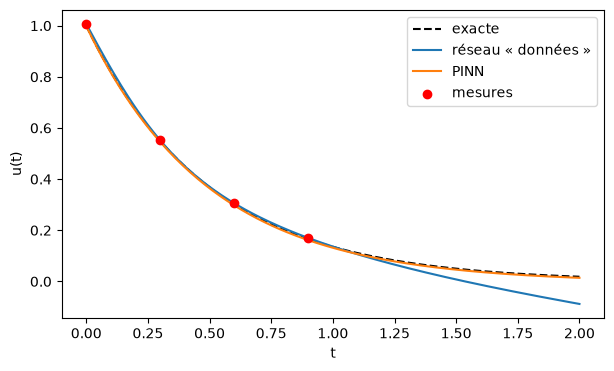

erreur max données : 0.1064
erreur max PINN : 0.0043


In [5]:
t_plot = torch.linspace(0, T, 200).unsqueeze(1)
with torch.no_grad():
    plt.figure(figsize=(7, 4))
    plt.plot(t_plot, u_exact(t_plot), "k--", label="exacte")
    plt.plot(t_plot, net_data(t_plot), label="réseau « données »")
    plt.plot(t_plot, net_pinn(t_plot), label="PINN")
    plt.scatter(t_obs, u_obs, c="r", zorder=3, label="mesures")
    plt.legend(); plt.xlabel("t"); plt.ylabel("u(t)"); plt.show()
    for name, n in [("données", net_data), ("PINN", net_pinn)]:
        err = (n(t_plot) - u_exact(t_plot)).abs().max().item()
        print(f"erreur max {name} : {err:.4f}")

**Question.** Pourquoi le réseau « données » diverge-t-il au-delà de $t=0{,}9$ alors que le PINN reste correct ?

## Exercices
1. **Oscillateur harmonique.** Résolvez $u'' + \omega^2 u = 0$, $u(0)=1$, $u'(0)=0$, $\omega=\pi$ sur $[0, 2]$. Indication : appelez `torch.autograd.grad` deux fois. Comparez à $\cos(\omega t)$.
2. **Problème inverse.** Rendez $k$ entraînable (`k = nn.Parameter(torch.tensor(0.5))`), ajoutez la perte sur les 4 mesures, et retrouvez $k$ à partir des données.
3. **Pondération.** Multipliez `loss_ic` par 10 puis par 0,1. Quel effet observez-vous ?

In [ ]:
# À compléter